# E1-v4 - MobileNetV3-Small AT-ADD Baseline Variant

This notebook implements the v4 preprocessing variant of the E1 MobileNetV3-Small baseline for the BTP audio deepfake detection project.

The model, frozen AT-ADD manifests, training procedure and evaluation protocol remain the same as E1. v4 changes only the audio frontend: **24 kHz input** and **repeat-based padding for clips shorter than 4 seconds**.

## Before running the notebook

The AT-ADD train/dev/eval manifests have already been prepared and verified outside this notebook.

This notebook reads the frozen manifests:

- `data/manifests/train_manifest.csv`
- `data/manifests/dev_manifest.csv`
- `data/manifests/eval_manifest.csv`

It does not recreate the dataset splits.

The manifests are frozen for E1 so that later E2/E3 comparisons use the same experimental partitions.

# 1. Environment and project paths

This section imports the experiment libraries and locates the project root.

The notebook searches upward from the current working directory for the prepared AT-ADD manifest directory, so it can be run from the project root or `notebooks/`.

All experiment outputs are kept separate from the raw dataset.

In [1]:
# 1. Imports and project paths

from pathlib import Path
import json
import math
import random
import time
import warnings
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

from sklearn.metrics import (
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    accuracy_score
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset,DataLoader
from torchvision.models import mobilenet_v3_small

warnings.filterwarnings("ignore")


def find_project_root(start_path):
    start_path=Path(start_path).resolve()

    candidates=[start_path]+list(start_path.parents)

    for candidate in candidates:
        if (
            (candidate/"data"/"manifests"/"train_manifest.csv").exists()
            and (candidate/"src"/"preprocessing"/"preprocess_atadd_v4.py").exists()
        ):
            return candidate

    raise FileNotFoundError(
        "Could not locate the Audio_DeepFake_Classification project root."
    )


PROJECT_ROOT=find_project_root(Path.cwd())

DATA_ROOT=PROJECT_ROOT/"data"
MANIFEST_DIR=DATA_ROOT/"manifests"

TRAIN_MANIFEST=MANIFEST_DIR/"train_manifest.csv"
DEV_MANIFEST=MANIFEST_DIR/"dev_manifest.csv"
EVAL_MANIFEST=MANIFEST_DIR/"eval_manifest.csv"

CHECKPOINT_DIR=PROJECT_ROOT/"checkpoints"/"E1"
EXPERIMENT_DIR=PROJECT_ROOT/"experiments"/"baselines"/"E1_v4"
RESULT_TABLE_DIR=PROJECT_ROOT/"results"/"tables"
RESULT_FIGURE_DIR=PROJECT_ROOT/"results"/"figures"
RESULT_LOG_DIR=PROJECT_ROOT/"results"/"logs"

for directory in [
    CHECKPOINT_DIR,
    EXPERIMENT_DIR,
    RESULT_TABLE_DIR,
    RESULT_FIGURE_DIR,
    RESULT_LOG_DIR
]:
    directory.mkdir(parents=True,exist_ok=True)


if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0,str(PROJECT_ROOT))

from src.preprocessing.preprocess_atadd_v4 import (
    cpu_prepare_waveform,
    GPULogMel,
    normalize_log_mel,
    compute_logmel_stats_gpu
)

print("Project root:",PROJECT_ROOT)
print("Manifest directory:",MANIFEST_DIR)


Project root: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification
Manifest directory: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/data/manifests


# 2. Verify the prepared dataset

The frozen AT-ADD manifests define the train, development, and evaluation partitions.

The notebook requires the core `name`, `label`, and `split` fields. If `file_id` is not present, it is derived from `name` so the same notebook works with the finalized manifests without modifying them.


In [2]:
# 2. Check the generated manifests before training

required_files=[
    TRAIN_MANIFEST,
    DEV_MANIFEST,
    EVAL_MANIFEST
]

for path in required_files:
    status="OK" if path.exists() else "MISSING"
    print(f"{status:<8} {path}")

if not TRAIN_MANIFEST.exists() or not DEV_MANIFEST.exists():
    raise FileNotFoundError(
        "Train/dev manifests were not found. "
        "Make sure the finalized AT-ADD manifests are present first."
    )


OK       /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/data/manifests/train_manifest.csv
OK       /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/data/manifests/dev_manifest.csv
OK       /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/data/manifests/eval_manifest.csv


# 3. Reproducibility and experiment configuration

E1 needs a fixed configuration so that later experiments can be compared fairly.

The important settings recorded here include:

- random seed
- audio sampling rate
- segment duration
- STFT parameters
- number of Mel bins
- batch size
- learning rate
- optimizer settings
- experiment version
- input preprocessing version

For the final E1 experiment, the fraction variables remain `None`, meaning the complete prepared partitions are used.



In [3]:
# 3. Reproducibility and training configuration

SEED=42


def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(SEED)

DEVICE=torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if DEVICE.type=="cuda":
    torch.backends.cudnn.deterministic=True
    torch.backends.cudnn.benchmark=False
    torch.set_float32_matmul_precision("high")
    print("Device:",torch.cuda.get_device_name(0))
else:
    print("Device: CPU")


EXPERIMENT_VERSION="v4.0"
INPUT_PREPROCESSING_VERSION="v4.0_24khz_repeat_pad"

BATCH_SIZE=32
EPOCHS=20
LEARNING_RATE=1e-3
WEIGHT_DECAY=1e-4
PATIENCE=5

NUM_WORKERS=4
PREFETCH_FACTOR=2

SAMPLE_RATE=24000
SEGMENT_SECONDS=4
NUM_SAMPLES=SAMPLE_RATE*SEGMENT_SECONDS

N_FFT=1024
WIN_LENGTH=600
HOP_LENGTH=240
N_MELS=80

LOG_EPS=1e-10

TRAIN_FRACTION=None
DEV_FRACTION=None
EVAL_FRACTION=None

STATS_MAX_FILES=None

print("Experiment version:",EXPERIMENT_VERSION)
print("Input preprocessing version:",INPUT_PREPROCESSING_VERSION)
print("Seed:",SEED)
print("Batch size:",BATCH_SIZE)
print("Epochs:",EPOCHS)
print("DataLoader workers:",NUM_WORKERS)
print("Device:",DEVICE)


Device: NVIDIA GeForce RTX 3060 Laptop GPU
Experiment version: v4.0
Input preprocessing version: v4.0_24khz_repeat_pad
Seed: 42
Batch size: 32
Epochs: 20
DataLoader workers: 4
Device: cuda


# 4. Load the reproducible manifests

The finalized AT-ADD train/dev/eval manifests are read directly from `data/manifests/`.

The notebook does not recreate or modify the prepared splits. The same manifests can therefore be reused by E2/E3 for fair comparison.

In [4]:
# 4. Load the reproducible AT-ADD manifests

train_df=pd.read_csv(TRAIN_MANIFEST)
dev_df=pd.read_csv(DEV_MANIFEST)

if EVAL_MANIFEST.exists():
    eval_df=pd.read_csv(EVAL_MANIFEST)
else:
    eval_df=pd.DataFrame()


LABEL_MAP={"real":0,"fake":1}
INV_LABEL_MAP={0:"real",1:"fake"}

required_columns={
    "name",
    "label",
    "split"
}

for name,df in [
    ("train",train_df),
    ("dev",dev_df),
    ("eval",eval_df)
]:
    if len(df)==0:
        continue

    missing_columns=required_columns-set(df.columns)

    if missing_columns:
        raise ValueError(
            f"{name} manifest is missing required columns: {sorted(missing_columns)}"
        )

    if "file_id" not in df.columns:
        df["file_id"]=df["name"].astype(str)

    unknown_labels=set(
        df["label"].dropna().astype(str).unique()
    )-set(LABEL_MAP)

    if unknown_labels:
        raise ValueError(
            f"{name} contains unknown labels: {unknown_labels}"
        )

    expected_split=name

    if not set(df["split"].astype(str).unique())<={
        expected_split
    }:
        raise ValueError(
            f"{name} manifest contains an unexpected split value."
        )

print("Train:",len(train_df))
print("Dev:",len(dev_df))
print("Eval:",len(eval_df))

print("\nTrain columns:")
print(train_df.columns.tolist())

print("\nFirst training entries:")
display(train_df.head())


Train: 46000
Dev: 36536
Eval: 44289

Train columns:
['name', 'type', 'label', 'source', 'source_id', 'speaker_id', 'generation_task', 'generator', 'caption', 'split', 'file_id']

First training entries:


,name,type,label,source,source_id,speaker_id,generation_task,generator,caption,split,file_id
0,ATADD_T2_Train_138205.flac,music,fake,-,-,-,TTM,AudioLDM2,someone is playing a high pitched melody on a ...,train,ATADD_T2_Train_138205.flac
1,ATADD_T2_Train_138216.flac,music,fake,-,-,-,TTM,AudioLDM2,This clip is an electronic guitar instrumental...,train,ATADD_T2_Train_138216.flac
2,ATADD_T2_Train_138218.flac,music,fake,-,-,-,TTM,AudioLDM2,This is a drum & bass music piece. There is a ...,train,ATADD_T2_Train_138218.flac
3,ATADD_T2_Train_138227.flac,music,fake,-,-,-,TTM,AudioLDM2,This is a country music piece. There is a fidd...,train,ATADD_T2_Train_138227.flac
4,ATADD_T2_Train_138230.flac,music,fake,-,-,-,TTM,AudioLDM2,This music is a spirited instrumental. The tem...,train,ATADD_T2_Train_138230.flac


## Dataset integrity checks

Before training, we check whether the paths recorded in the manifests actually point to audio files.

A missing file should be investigated before the final experiment rather than silently skipped.


In [5]:
# 5. Verify that manifest paths point to existing files

def audio_path_from_row(row,project_root):
    return (
        project_root
        /"data"
        /"raw"
        /"AT_ADD"
        /str(row["split"])
        /str(row["name"])
    )


def check_audio_files(df,project_root):
    if len(df)==0:
        return 0

    return sum(
        not audio_path_from_row(row,project_root).exists()
        for _,row in df.iterrows()
    )


for name,df in [
    ("train",train_df),
    ("dev",dev_df),
    ("eval",eval_df)
]:
    if len(df)==0:
        continue

    missing=check_audio_files(df,PROJECT_ROOT)

    print(
        f"{name:<8}: {missing} missing audio files"
    )

    if missing>0:
        raise FileNotFoundError(
            f"{name} contains {missing} missing audio files."
        )


train   : 0 missing audio files
dev     : 0 missing audio files
eval    : 0 missing audio files


## Class and generator distribution

The class distribution is inspected before training because the prepared AT-ADD subset is not perfectly balanced.

Fake-generator coverage is also checked to confirm that the evaluation generators remain unseen during training and development. No split is modified here.

In [6]:
# 6. Inspect class, type and generator information

def show_split_summary(df,name):
    print(f"\n{name.upper()}")
    print("-"*50)
    print("Files:",len(df))

    if "label" in df.columns:
        print("\nClass counts:")
        print(df["label"].value_counts(dropna=False))

    if "type" in df.columns:
        print("\nAudio type counts:")
        print(df["type"].value_counts(dropna=False))

    if "generator" in df.columns:
        fake_df=df[df["label"]=="fake"]
        print("\nFake generators:",fake_df["generator"].nunique())

show_split_summary(train_df,"train")
show_split_summary(dev_df,"dev")

if len(eval_df):
    show_split_summary(eval_df,"eval")

train_generators=set(train_df.loc[train_df["label"]=="fake","generator"])
dev_generators=set(dev_df.loc[dev_df["label"]=="fake","generator"])
eval_generators=set(eval_df.loc[eval_df["label"]=="fake","generator"]) if len(eval_df) else set()

print("\nTrain ∩ Dev generators:",len(train_generators&dev_generators))
print("Train ∩ Eval generators:",len(train_generators&eval_generators))
print("Dev ∩ Eval generators:",len(dev_generators&eval_generators))

if len(eval_df):
    assert len(train_generators&eval_generators)==0
    assert len(dev_generators&eval_generators)==0

print("\nAT-ADD generator-disjoint evaluation check: PASS")


TRAIN
--------------------------------------------------
Files: 46000

Class counts:
label
fake    30000
real    16000
Name: count, dtype: int64

Audio type counts:
type
speech     24000
music       8000
singing     7000
sound       7000
Name: count, dtype: int64

Fake generators: 29

DEV
--------------------------------------------------
Files: 36536

Class counts:
label
fake    30000
real     6536
Name: count, dtype: int64

Audio type counts:
type
speech     22000
singing     5000
sound       5000
music       4536
Name: count, dtype: int64

Fake generators: 29

EVAL
--------------------------------------------------
Files: 44289

Class counts:
label
fake    37753
real     6536
Name: count, dtype: int64

Audio type counts:
type
speech     27000
singing     6753
sound       6000
music       4536
Name: count, dtype: int64

Fake generators: 38

Train ∩ Dev generators: 29
Train ∩ Eval generators: 0
Dev ∩ Eval generators: 0

AT-ADD generator-disjoint evaluation check: PASS


# 5. E1-v4 input preprocessing

E1-v4 uses the same fixed audio-to-log-Mel pipeline as E1, but changes the frontend to reduce the potential zero-padding shortcut:

```text
FLAC → mono → 24 kHz → fixed 4 s crop/repeat-padding → GPU STFT → 80-bin Mel → log power → training-set normalization
```

For 24 kHz audio, the 25 ms analysis window and 10 ms hop are retained by using `WIN_LENGTH=600` and `HOP_LENGTH=240`. `N_FFT=1024` and `N_MELS=80` remain unchanged.

# 6. AT-ADD v4 preprocessing module

Audio loading, mono conversion, 24 kHz resampling, fixed-length crop/repeat-padding, GPU STFT, Mel extraction and normalization are implemented in `src/preprocessing/preprocess_atadd_v4.py`.

Short clips are padded by repeating their waveform rather than appending zeros. This is a preprocessing change only; no robustness transformations are introduced.

In [7]:
# 6. Initialize the shared GPU log-Mel extractor

gpu_logmel=GPULogMel(
    sample_rate=SAMPLE_RATE,
    n_fft=N_FFT,
    win_length=WIN_LENGTH,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
    log_eps=LOG_EPS
).to(DEVICE)

print("GPU log-Mel device:",gpu_logmel.mel_filter.device)


GPU log-Mel device: cuda:0


# 7. Optional smoke-test subsets

The following settings allow a small subset of the data to be used while debugging the pipeline.

For example:

```python
TRAIN_FRACTION=0.02
DEV_FRACTION=0.02
```

can be used to verify that the complete training loop works.

For the **actual E1 experiment**, keep all three fraction variables as `None`.

This prevents a debugging run from accidentally being treated as the final baseline.


In [8]:
# 7. Optional smoke-test subsets
# Keep these as None for the final experiment (In code cell 3)

def take_fraction(df,fraction,seed=42):
    if fraction is None or fraction>=1.0:
        return df.copy()

    if fraction<=0:
        raise ValueError("Fraction must be greater than 0.")

    pieces=[]

    for label,group in df.groupby("label"):
        n=max(1,int(len(group)*fraction))
        pieces.append(group.sample(n=n,random_state=seed))

    return pd.concat(pieces).sample(
        frac=1.0,
        random_state=seed
    ).reset_index(drop=True)


train_run_df=take_fraction(train_df,TRAIN_FRACTION,SEED)
dev_run_df=take_fraction(dev_df,DEV_FRACTION,SEED)

if len(eval_df):
    eval_run_df=take_fraction(eval_df,EVAL_FRACTION,SEED)
else:
    eval_run_df=eval_df

print("Train:",len(train_run_df))
print("Dev:",len(dev_run_df))
print("Eval:",len(eval_run_df))


Train: 46000
Dev: 36536
Eval: 44289


# 8. PyTorch dataset and DataLoaders

The dataset returns a fixed-length waveform, its binary label and the file ID.

CPU workers handle file decoding, resampling and crop/padding. Batched waveforms are then moved to the GPU for STFT, Mel filtering, log compression and normalization.

Training uses random crops; development/evaluation use center crops.

In [9]:
# 8. PyTorch waveform dataset and reproducible DataLoaders

class WaveformDataset(Dataset):

    def __init__(self,df,training):
        self.df=df.reset_index(drop=True)
        self.training=training

    def __len__(self):
        return len(self.df)

    def __getitem__(self,index):
        row=self.df.iloc[index]

        audio_path=audio_path_from_row(
            row,
            PROJECT_ROOT
        )

        waveform=cpu_prepare_waveform(
            audio_path,
            sample_rate=SAMPLE_RATE,
            segment_seconds=SEGMENT_SECONDS,
            training=self.training
        )

        label=LABEL_MAP[row["label"]]

        return (
            waveform,
            torch.tensor(
                label,
                dtype=torch.long
            ),
            row["file_id"]
        )


def seed_worker(worker_id):
    worker_seed=torch.initial_seed()%2**32

    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_waveform_loader(df,training):

    dataset=WaveformDataset(
        df,
        training
    )

    loader_kwargs={
        "batch_size":BATCH_SIZE,
        "shuffle":training,
        "num_workers":NUM_WORKERS,
        "pin_memory":DEVICE.type=="cuda",
        "worker_init_fn":seed_worker
    }

    generator=torch.Generator()
    generator.manual_seed(SEED)

    if NUM_WORKERS>0:
        loader_kwargs["persistent_workers"]=True
        loader_kwargs["prefetch_factor"]=PREFETCH_FACTOR

    return DataLoader(
        dataset,
        generator=generator,
        **loader_kwargs
    )


# 9. Compute or load training-set Log-Mel statistics

Because v4 changes both the sample rate and short-audio padding strategy, **E1 statistics must not be reused**. The normalization statistics below are computed from the v4 training representation only.

In [10]:
# 9. Compute or load training-set Log-Mel statistics

stats_loader=make_waveform_loader(
    train_run_df,
    False
)

stats_path=EXPERIMENT_DIR/"E1_ATADD_logmel_stats_v4.json"

stats_compatible=False

if stats_path.exists() and STATS_MAX_FILES is None:
    with stats_path.open("r",encoding="utf-8") as f:
        stats=json.load(f)

    stats_compatible=(
        stats.get("version")==INPUT_PREPROCESSING_VERSION
        and stats.get("train_samples")==len(train_run_df)
        and stats.get("sample_rate")==SAMPLE_RATE
        and stats.get("segment_seconds")==SEGMENT_SECONDS
        and stats.get("n_fft")==N_FFT
        and stats.get("win_length")==WIN_LENGTH
        and stats.get("hop_length")==HOP_LENGTH
        and stats.get("n_mels")==N_MELS
    )

if stats_compatible:
    MEL_MEAN=float(stats["mean"])
    MEL_STD=float(stats["std"])
    print("Loaded compatible cached training statistics.")

else:
    stats_batches=None

    if STATS_MAX_FILES is not None:
        stats_batches=max(
            1,
            math.ceil(
                STATS_MAX_FILES/BATCH_SIZE
            )
        )

    MEL_MEAN,MEL_STD=compute_logmel_stats_gpu(
        stats_loader,
        gpu_logmel,
        DEVICE,
        stats_batches
    )

    stats={
        "version":INPUT_PREPROCESSING_VERSION,
        "mean":MEL_MEAN,
        "std":MEL_STD,
        "seed":SEED,
        "train_samples":len(train_run_df),
        "sample_rate":SAMPLE_RATE,
        "segment_seconds":SEGMENT_SECONDS,
        "n_fft":N_FFT,
        "win_length":WIN_LENGTH,
        "hop_length":HOP_LENGTH,
        "n_mels":N_MELS,
        "feature_device":"cuda" if DEVICE.type=="cuda" else "cpu"
    }

    with stats_path.open("w",encoding="utf-8") as f:
        json.dump(stats,f,indent=2)

print("Mel mean:",MEL_MEAN)
print("Mel std :",MEL_STD)

if not np.isfinite(MEL_MEAN) or not np.isfinite(MEL_STD) or MEL_STD<=0:
    raise ValueError(
        "Invalid Log-Mel normalization statistics."
    )


Mel mean: -9.191030070182308
Mel std : 6.850966223389033


## Visual sanity check

Before training, one training example is converted through the exact E1 preprocessing path. This confirms the waveform length, log-Mel dimensions and normalization pipeline.

Audio: ATADD_T2_Train_138205.flac
Type: music
Label: fake
Generator: AudioLDM2
Waveform shape: torch.Size([96000])
Log-Mel shape: (80, 401)


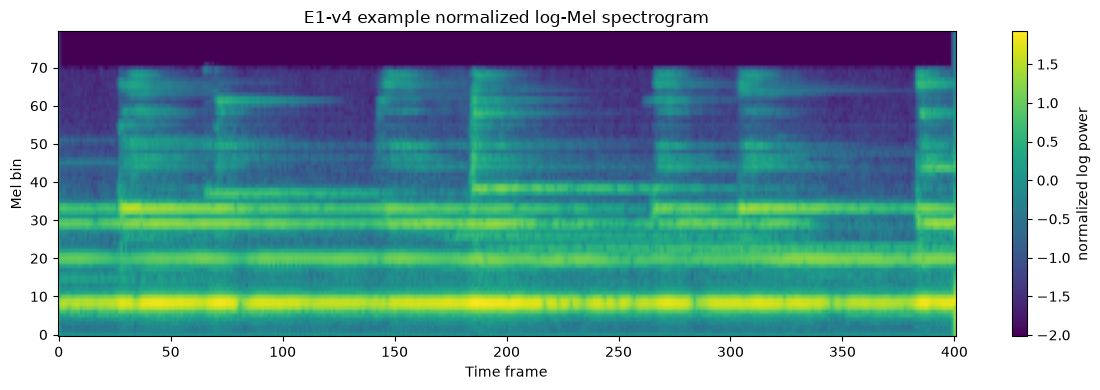

In [11]:
# 10. Visual sanity check for the GPU input representation

sample_row=train_run_df.iloc[0]

sample_path=audio_path_from_row(
    sample_row,
    PROJECT_ROOT
)

sample_wave=cpu_prepare_waveform(
    sample_path,
    sample_rate=SAMPLE_RATE,
    segment_seconds=SEGMENT_SECONDS,
    training=False
)

sample_batch=sample_wave.unsqueeze(0).to(
    DEVICE,
    non_blocking=True
)

with torch.no_grad():
    sample_logmel=gpu_logmel(
        sample_batch
    )

sample_logmel=normalize_log_mel(
    sample_logmel,
    MEL_MEAN,
    MEL_STD
)

sample_logmel=sample_logmel[0].cpu().numpy()

print("Audio:",sample_path.name)
print("Type:",sample_row["type"])
print("Label:",sample_row["label"])
print("Generator:",sample_row["generator"])
print("Waveform shape:",sample_wave.shape)
print("Log-Mel shape:",sample_logmel.shape)

plt.figure(figsize=(12,4))
plt.imshow(
    sample_logmel,
    origin="lower",
    aspect="auto"
)
plt.title("E1-v4 example normalized log-Mel spectrogram")
plt.xlabel("Time frame")
plt.ylabel("Mel bin")
plt.colorbar(label="normalized log power")
plt.tight_layout()
plt.show()


In [12]:
# 11. Build the training and development DataLoaders

train_loader=make_waveform_loader(train_run_df,True)

train_eval_loader=make_waveform_loader(train_run_df,False)

dev_loader=make_waveform_loader(dev_run_df,False)

print("Training batches:",len(train_loader))
print("Training evaluation batches:",len(train_eval_loader))
print("Development batches:",len(dev_loader))

Training batches: 1438
Training evaluation batches: 1438
Development batches: 1142


In [13]:
# 12. Build MobileNetV3-Small for one-channel spectrogram input

class MobileNetV3SmallAudio(nn.Module):
    def __init__(self,num_classes=2):
        super().__init__()

        self.backbone=mobilenet_v3_small(
            weights=None,
            num_classes=num_classes
        )

        # Replace the RGB input layer with a single-channel input layer
        old_conv=self.backbone.features[0][0]

        new_conv=nn.Conv2d(
            in_channels=1,
            out_channels=old_conv.out_channels,
            kernel_size=old_conv.kernel_size,
            stride=old_conv.stride,
            padding=old_conv.padding,
            dilation=old_conv.dilation,
            groups=old_conv.groups,
            bias=False
        )

        self.backbone.features[0][0]=new_conv

    def forward(self,x):
        return self.backbone(x)


model=MobileNetV3SmallAudio(num_classes=2).to(DEVICE)

total_params=sum(p.numel() for p in model.parameters())
trainable_params=sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")


Total parameters: 1,519,618
Trainable parameters: 1,519,618


# 13. Loss function and optimizer

The training labels are slightly imbalanced, so E1 uses class-weighted cross entropy.

The optimizer is AdamW with a small weight decay.

A `ReduceLROnPlateau` scheduler reduces the learning rate when development Macro-F1 stops improving.

The development set is used for model selection; the evaluation set is not used to choose the model.


In [14]:
# 13. Loss and optimizer

class_counts=train_run_df["label"].map(LABEL_MAP).value_counts().sort_index().values.astype(np.float64)

class_weights=class_counts.sum()/(len(class_counts)*class_counts)

class_weights=torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE
)

criterion=nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer=torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

print("Class counts [real, fake]:",class_counts.astype(int))
print("Class weights:",class_weights.detach().cpu().numpy())

Class counts [real, fake]: [16000 30000]
Class weights: [1.4375     0.76666665]


# 14. Evaluation metrics

The main E1 metrics are:

### Macro-F1

Macro-F1 calculates F1 separately for real and fake classes and then averages them. This prevents the larger class from dominating the summary score.

### AUROC

AUROC measures how well the model ranks fake and real examples across decision thresholds.

### EER

Equal Error Rate is calculated from the ROC curve by finding the point where false-positive and false-negative rates are approximately equal.

Accuracy is also recorded, but it is not the primary metric for comparing the detector.


In [15]:
# 14. Evaluation metrics

def compute_eer(y_true,scores):
    y_true=np.asarray(y_true)
    scores=np.asarray(scores)

    if len(np.unique(y_true))<2:
        return float("nan"),float("nan")

    fpr,tpr,thresholds=roc_curve(y_true,scores)
    fnr=1.0-tpr

    index=np.nanargmin(np.abs(fpr-fnr))

    eer=float((fpr[index]+fnr[index])/2.0)
    threshold=float(thresholds[index])

    return eer,threshold


def calculate_metrics(y_true,scores,threshold=0.5):
    y_true=np.asarray(y_true).astype(int)
    scores=np.asarray(scores).astype(float)

    if len(y_true)==0:
        raise ValueError("Cannot calculate metrics on an empty dataset.")

    predictions=(scores>=threshold).astype(int)

    metrics={
        "macro_f1":float(f1_score(y_true,predictions,average="macro",zero_division=0)),
        "accuracy":float(accuracy_score(y_true,predictions)),
        "auroc":float("nan")
    }

    if len(np.unique(y_true))==2:
        metrics["auroc"]=float(roc_auc_score(y_true,scores))

    eer,eer_threshold=compute_eer(y_true,scores)

    metrics["eer"]=eer
    metrics["eer_threshold"]=eer_threshold

    return metrics,predictions


@torch.no_grad()
def waveform_batch_to_features(waveforms):
    waveforms=waveforms.to(DEVICE,non_blocking=True)

    log_mel=gpu_logmel(waveforms)
    log_mel=normalize_log_mel(log_mel,MEL_MEAN,MEL_STD)

    return log_mel.unsqueeze(1)


@torch.no_grad()
def run_evaluation(model,loader,criterion=None,description="Evaluating"):
    model.eval()

    total_loss=0.0
    total_items=0

    all_labels=[]
    all_scores=[]
    all_file_ids=[]

    for waveforms,y,file_ids in tqdm(loader,desc=description,leave=False):
        y=y.to(DEVICE,non_blocking=True)

        x=waveform_batch_to_features(waveforms)

        with autocast_context():
            logits=model(x)

            if criterion is not None:
                loss=criterion(logits,y)

        if criterion is not None:
            total_loss+=float(loss.item())*x.size(0)

        scores=torch.softmax(logits.float(),dim=1)[:,1]

        all_labels.extend(y.cpu().numpy().tolist())
        all_scores.extend(scores.float().cpu().numpy().tolist())
        all_file_ids.extend(list(file_ids))

        total_items+=x.size(0)

    avg_loss=total_loss/max(total_items,1)

    metrics,predictions=calculate_metrics(all_labels,all_scores)

    metrics["loss"]=avg_loss

    return metrics,np.asarray(all_labels),np.asarray(all_scores),predictions,all_file_ids

## GPU training and GPU feature extraction

CPU DataLoader workers handle audio decoding, resampling and crop/repeat-padding. Batched STFT, Mel extraction, log compression and normalization run on the GPU when CUDA is available.

In [16]:
# 15. Mixed-precision training setup

amp_enabled=DEVICE.type=="cuda"

scaler=torch.amp.GradScaler(
    "cuda",
    enabled=amp_enabled
)

def autocast_context():
    return torch.amp.autocast(
        device_type=DEVICE.type,
        dtype=torch.float16,
        enabled=amp_enabled
    )

# 16. Training loop

The model is trained on the training partition and evaluated on the development partition after every epoch.

The best checkpoint is selected using **development Macro-F1**.

Early stopping is used when development Macro-F1 does not improve for the configured patience period.

The evaluation partition is not used during model selection.


In [17]:
# 16. Train one epoch

def train_one_epoch(model,loader):

    model.train()

    running_loss=0.0
    correct=0
    total_items=0

    progress=tqdm(loader,desc="Training",leave=False)

    for waveforms,y,_ in progress:

        y=y.to(DEVICE,non_blocking=True)

        x=waveform_batch_to_features(waveforms)

        optimizer.zero_grad(set_to_none=True)

        with autocast_context():
            logits=model(x)
            loss=criterion(logits,y)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        predictions=torch.argmax(logits,dim=1)

        correct+=(predictions==y).sum().item()
        running_loss+=float(loss.item())*x.size(0)
        total_items+=x.size(0)

        progress.set_postfix(loss=f"{loss.item():.4f}")

    train_loss=running_loss/max(total_items,1)
    train_accuracy=correct/max(total_items,1)

    return train_loss,train_accuracy

In [18]:
# 17. Train E1-v4 and save the best development checkpoint

history=[]

best_dev_f1=-np.inf
best_epoch=-1
epochs_without_improvement=0

best_checkpoint_path=CHECKPOINT_DIR/"E1_MobileNetV3Small_ATADD_v4_best.pt"

for epoch in range(1,EPOCHS+1):

    start_time=time.time()

    train_loss,train_accuracy=train_one_epoch(model,train_loader)

    dev_metrics,dev_y,dev_scores,dev_preds,dev_ids=run_evaluation(model,dev_loader,criterion)

    scheduler.step(dev_metrics["macro_f1"])

    epoch_time=time.time()-start_time

    row={
        "epoch":epoch,
        "train_loss":train_loss,
        "train_accuracy":train_accuracy,
        "dev_loss":dev_metrics["loss"],
        "dev_accuracy":dev_metrics["accuracy"],
        "dev_macro_f1":dev_metrics["macro_f1"],
        "dev_auroc":dev_metrics["auroc"],
        "dev_eer":dev_metrics["eer"],
        "lr":optimizer.param_groups[0]["lr"],
        "epoch_seconds":epoch_time
    }

    history.append(row)

    history_df=pd.DataFrame(history)
    history_path=EXPERIMENT_DIR/"E1_ATADD_training_history_v4.csv"
    history_df.to_csv(history_path,index=False)

    print(f"Epoch {epoch:02d}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_accuracy:.4f}")
    print(f"Dev Loss: {dev_metrics['loss']:.4f} | Dev Acc: {dev_metrics['accuracy']:.4f}")
    print(f"Dev Macro-F1: {dev_metrics['macro_f1']:.4f} | Dev AUROC: {dev_metrics['auroc']:.4f} | Dev EER: {dev_metrics['eer']:.4f}")
    print(f"Learning Rate: {optimizer.param_groups[0]['lr']:.6f} | Time: {epoch_time:.1f}s")

    if dev_metrics["macro_f1"]>best_dev_f1:

        best_dev_f1=dev_metrics["macro_f1"]
        best_epoch=epoch
        epochs_without_improvement=0

        torch.save(
            {
                "experiment":"E1-v4",
                "experiment_version":EXPERIMENT_VERSION,
                "input_preprocessing_version":INPUT_PREPROCESSING_VERSION,
                "model_name":"MobileNetV3-Small",
                "epoch":epoch,
                "model_state_dict":model.state_dict(),
                "optimizer_state_dict":optimizer.state_dict(),
                "scheduler_state_dict":scheduler.state_dict(),
                "best_dev_macro_f1":best_dev_f1,
                "config":{
                    "seed":SEED,
                    "sample_rate":SAMPLE_RATE,
                    "segment_seconds":SEGMENT_SECONDS,
                    "n_fft":N_FFT,
                    "win_length":WIN_LENGTH,
                    "hop_length":HOP_LENGTH,
                    "n_mels":N_MELS,
                    "batch_size":BATCH_SIZE,
                    "learning_rate":LEARNING_RATE,
                    "weight_decay":WEIGHT_DECAY,
                    "mel_mean":MEL_MEAN,
                    "mel_std":MEL_STD,
                    "feature_extraction":"GPU_STFT_Mel"
                }
            },
            best_checkpoint_path
        )

        print("  -> saved new best checkpoint")

    else:
        epochs_without_improvement+=1

    print()

    if epochs_without_improvement>=PATIENCE:
        print(f"Early stopping at epoch {epoch}.")
        break

history_df=pd.DataFrame(history)
history_path=EXPERIMENT_DIR/"E1_ATADD_training_history_v4.csv"
history_df.to_csv(history_path,index=False)

print("Best development Macro-F1:",best_dev_f1)
print("Best epoch:",best_epoch)
print("Checkpoint:",best_checkpoint_path)
print("History:",history_path)

Training:   0%|          | 0/1438 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/1142 [00:00<?, ?it/s]

Epoch 01/20
Train Loss: 0.3786 | Train Acc: 0.8261
Dev Loss: 0.3018 | Dev Acc: 0.8787
Dev Macro-F1: 0.8185 | Dev AUROC: 0.9445 | Dev EER: 0.1328
Learning Rate: 0.001000 | Time: 121.6s
  -> saved new best checkpoint



Training:   0%|          | 0/1438 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/1142 [00:00<?, ?it/s]

...

Evaluating:   0%|          | 0/1142 [00:00<?, ?it/s]

Epoch 19/20
Train Loss: 0.0231 | Train Acc: 0.9912
Dev Loss: 0.0960 | Dev Acc: 0.9728
Dev Macro-F1: 0.9528 | Dev AUROC: 0.9937 | Dev EER: 0.0387
Learning Rate: 0.000250 | Time: 110.5s
  -> saved new best checkpoint



Training:   0%|          | 0/1438 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/1142 [00:00<?, ?it/s]

Epoch 20/20
Train Loss: 0.0193 | Train Acc: 0.9926
Dev Loss: 0.0863 | Dev Acc: 0.9706
Dev Macro-F1: 0.9520 | Dev AUROC: 0.9965 | Dev EER: 0.0295
Learning Rate: 0.000250 | Time: 111.0s

Best development Macro-F1: 0.9528367467485043
Best epoch: 19
Checkpoint: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/checkpoints/E1/E1_MobileNetV3Small_ATADD_v4_best.pt
History: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/E1_v4/E1_ATADD_training_history_v4.csv


## Training curves

The training curves provide a quick way to identify:

- underfitting
- overfitting
- unstable optimization
- whether the development performance has stopped improving

These plots are saved under `results/figures/` for the project record.


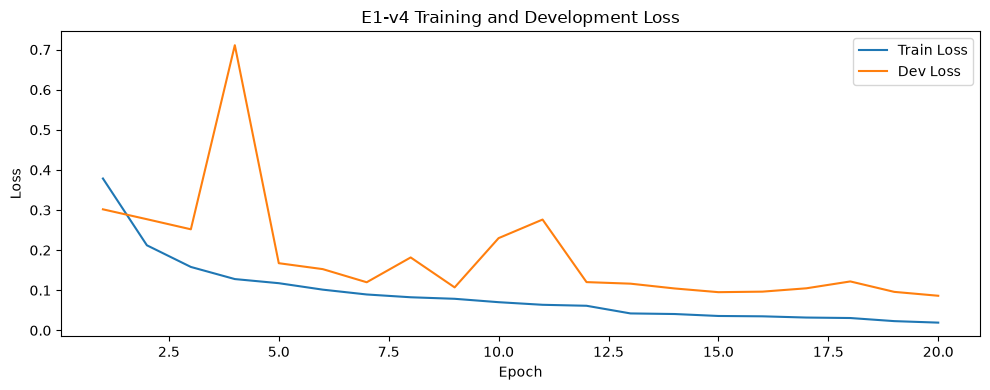

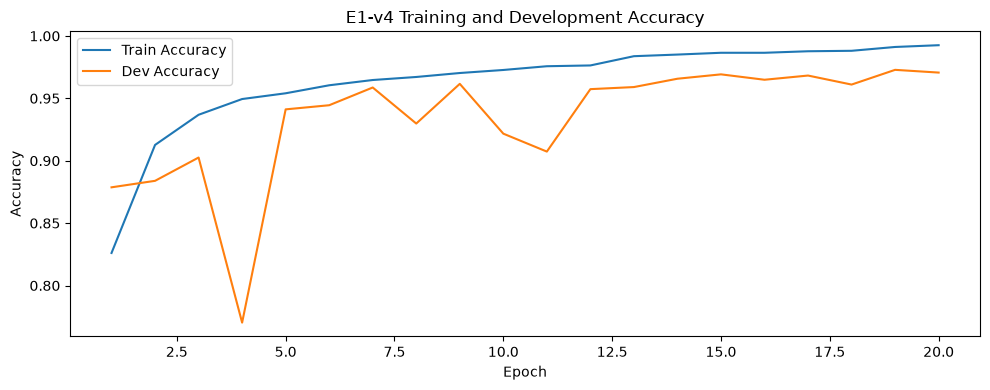

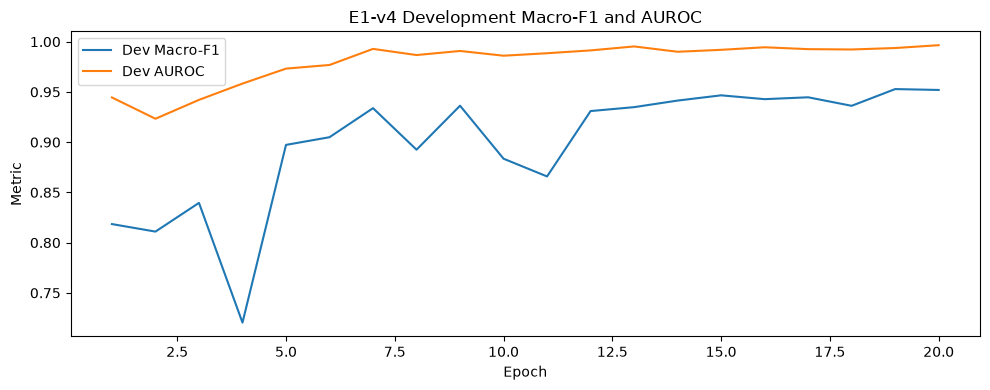

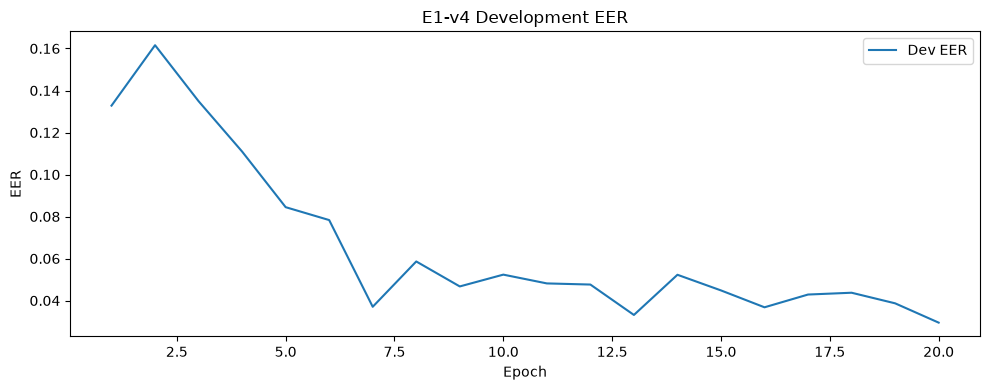

In [19]:
# 18. Plot and save training curves

plt.figure(figsize=(10,4))
plt.plot(history_df["epoch"],history_df["train_loss"],label="Train Loss")
plt.plot(history_df["epoch"],history_df["dev_loss"],label="Dev Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("E1-v4 Training and Development Loss")
plt.legend()
plt.tight_layout()

loss_fig_path=RESULT_FIGURE_DIR/"E1_ATADD_training_loss_v4.png"
plt.savefig(loss_fig_path,dpi=200)
plt.show()


plt.figure(figsize=(10,4))
plt.plot(history_df["epoch"],history_df["train_accuracy"],label="Train Accuracy")
plt.plot(history_df["epoch"],history_df["dev_accuracy"],label="Dev Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("E1-v4 Training and Development Accuracy")
plt.legend()
plt.tight_layout()

accuracy_fig_path=RESULT_FIGURE_DIR/"E1_ATADD_training_accuracy_v4.png"
plt.savefig(accuracy_fig_path,dpi=200)
plt.show()


plt.figure(figsize=(10,4))
plt.plot(history_df["epoch"],history_df["dev_macro_f1"],label="Dev Macro-F1")
plt.plot(history_df["epoch"],history_df["dev_auroc"],label="Dev AUROC")
plt.xlabel("Epoch")
plt.ylabel("Metric")
plt.title("E1-v4 Development Macro-F1 and AUROC")
plt.legend()
plt.tight_layout()

metric_fig_path=RESULT_FIGURE_DIR/"E1_ATADD_validation_metrics_v4.png"
plt.savefig(metric_fig_path,dpi=200)
plt.show()


plt.figure(figsize=(10,4))
plt.plot(history_df["epoch"],history_df["dev_eer"],label="Dev EER")
plt.xlabel("Epoch")
plt.ylabel("EER")
plt.title("E1-v4 Development EER")
plt.legend()
plt.tight_layout()

eer_fig_path=RESULT_FIGURE_DIR/"E1_ATADD_validation_eer_v4.png"
plt.savefig(eer_fig_path,dpi=200)
plt.show()

# 19. Final development evaluation

After training, we reload the checkpoint with the best development Macro-F1.

All reported development metrics below therefore correspond to the selected E1 checkpoint rather than simply the final training epoch.


In [20]:
# 19. Load the best E1-v4 checkpoint

checkpoint=torch.load(best_checkpoint_path,map_location=DEVICE,weights_only=False)

model.load_state_dict(checkpoint["model_state_dict"])

print("Loaded checkpoint from epoch:",checkpoint["epoch"])
print("Best development Macro-F1:",checkpoint["best_dev_macro_f1"])

Loaded checkpoint from epoch: 19
Best development Macro-F1: 0.9528367467485043


## Development-set results

These are the metrics we use to understand how well the clean E1 baseline learned the real/fake classification task.

The development predictions are also saved so that later analysis can inspect individual recordings.


In [21]:
# 20. Final development-set evaluation

val_metrics,val_y,val_scores,val_preds,val_ids=run_evaluation(model,dev_loader,criterion)

print("E1-v4 validation results")
print("-"*30)

for key,value in val_metrics.items():
    print(f"{key:<16}: {value:.6f}")

with open(
    EXPERIMENT_DIR/"E1_ATADD_validation_metrics_v4.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(val_metrics,f,indent=2)


Evaluating:   0%|          | 0/1142 [00:00<?, ?it/s]

E1-v4 validation results
------------------------------
macro_f1        : 0.952837
accuracy        : 0.972821
auroc           : 0.993695
eer             : 0.038688
eer_threshold   : 0.967287
loss            : 0.096010


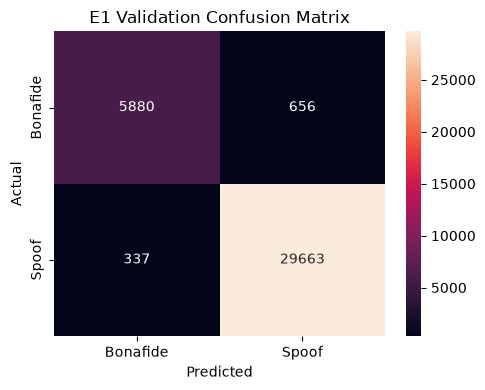

[[ 5880   656]
 [  337 29663]]


In [22]:
# 21. Validation confusion matrix

cm=confusion_matrix(val_y,val_preds)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Bonafide","Spoof"],
    yticklabels=["Bonafide","Spoof"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("E1 Validation Confusion Matrix")
plt.tight_layout()

cm_path=RESULT_FIGURE_DIR/"E1_validation_confusion_matrix_v1.png"
plt.savefig(cm_path,dpi=200)
plt.show()

print(cm)


## Save development predictions

Saving the individual prediction scores is useful later when comparing E1 with E2/E3 or investigating difficult examples.

The file contains the model's fake score, predicted class and ground-truth label for each development recording.


In [23]:
# 22. Save validation predictions for later analysis

val_predictions_df=pd.DataFrame({
    "file_id":val_ids,
    "label":val_y,
    "spoof_score":val_scores,
    "prediction":val_preds
})

val_predictions_path=EXPERIMENT_DIR/"E1_ATADD_dev_predictions_v4.csv"
val_predictions_df.to_csv(
    val_predictions_path,
    index=False
)

print("Saved:",val_predictions_path)


Saved: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/E1_v4/E1_ATADD_dev_predictions_v4.csv


# 23. Official evaluation inference

The official evaluation partition is processed only after the E1 checkpoint has been selected using the development set.

If evaluation labels are available, the notebook calculates the same metrics used on the development set.

If labels are not available, it saves prediction scores without inventing evaluation metrics.


In [24]:
# 23. Prepare the official evaluation DataLoader

eval_scores=np.asarray([])
eval_labels=np.asarray([])
eval_ids=[]
eval_analysis=pd.DataFrame()

if len(eval_run_df):
    eval_loader=make_waveform_loader(
        eval_run_df,
        False
    )
else:
    eval_loader=None

print(
    "Evaluation loader ready:",
    eval_loader is not None
)


Evaluation loader ready: True


In [25]:
# 24. Run official evaluation inference

if len(eval_run_df):

    model.eval()

    eval_scores=[]
    eval_labels=[]
    eval_ids=[]

    with torch.no_grad():

        for waveforms,y,file_ids in tqdm(
            eval_loader,
            desc="Official evaluation"
        ):

            y=y.to(
                DEVICE,
                non_blocking=True
            )

            x=waveform_batch_to_features(
                waveforms
            )

            with autocast_context():
                logits=model(x)

            scores=torch.softmax(logits.float(),dim=1)[:,1]

            eval_scores.extend(scores.float().cpu().numpy().tolist())

            eval_labels.extend(y.cpu().numpy().tolist())

            eval_ids.extend(list(file_ids))

    eval_scores=np.asarray(eval_scores)

    eval_labels=np.asarray(eval_labels)

    eval_predictions=(eval_scores>=0.5).astype(int)

    eval_output=pd.DataFrame({
        "file_id":eval_ids,
        "label":eval_labels,
        "spoof_score":eval_scores,
        "prediction":eval_predictions
    })

    eval_output_path=(
        EXPERIMENT_DIR/
        "E1_ATADD_eval_predictions_v4.csv"
    )

    eval_output.to_csv(
        eval_output_path,
        index=False
    )

    print(
        "Saved:",
        eval_output_path
    )

    if len(np.unique(eval_labels))==2:

        eval_metrics,_=calculate_metrics(
            eval_labels,
            eval_scores
        )

        print("\nAT-ADD evaluation results")
        print("-"*30)

        for key,value in eval_metrics.items():
            print(
                f"{key:<16}: {value:.6f}"
            )

        with open(
            EXPERIMENT_DIR/
            "E1_ATADD_eval_metrics_v4.json",
            "w",
            encoding="utf-8"
        ) as f:
            json.dump(
                eval_metrics,
                f,
                indent=2
            )

    else:
        print(
            "\nEvaluation labels do not contain both classes."
        )

else:
    print(
        "No evaluation manifest was found."
    )

Official evaluation:   0%|          | 0/1385 [00:00<?, ?it/s]

Saved: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/E1_v4/E1_ATADD_eval_predictions_v4.csv

AT-ADD evaluation results
------------------------------
macro_f1        : 0.677588
accuracy        : 0.757005
auroc           : 0.875002
eer             : 0.199250
eer_threshold   : 0.132739


AT-ADD generator generalization
--------------------------------------------------
Train generators: 29
Dev generators: 29
Eval generators: 38
Train ∩ Eval: 0
Dev ∩ Eval: 0
Unseen-generator evaluation check: PASS

Per-type evaluation results
--------------------------------------------------


,type,samples,real_samples,fake_samples,macro_f1,auroc,eer
0,music,4536,536,4000,0.390667,0.559273,0.460910
1,singing,6753,2000,4753,0.824004,0.944726,0.124987
2,sound,6000,2000,4000,0.536491,0.743489,0.343625
3,speech,27000,2000,25000,0.681378,0.928926,0.141980



Mean per-type Macro-F1: 0.608135

Per-generator fake-sample results
--------------------------------------------------


,generator,audio_type,samples,fake_detected,fake_missed,fake_recall,mean_fake_score
26,SSM-TTM,music,1000,3,997,0.003000,0.006916
0,ACE-Step,music,1000,129,871,0.129000,0.137392
1,Auffusion,sound,1000,147,853,0.147000,0.153066
2,BigVGAN,speech,1000,197,803,0.197000,0.206226
34,UniAudio2,sound,1000,349,651,0.349000,0.358754
35,Uniaudio2,music,1000,356,644,0.356000,0.374588
21,MeanAudio,sound,1000,425,575,0.425000,0.442687
33,StyleTTS2,speech,1000,515,485,0.515000,0.514544
16,IndexTTS2,speech,1000,569,431,0.569000,0.563120
3,Both-Ears-Wide-Open,sound,1000,608,392,0.608000,0.600908


Saved generator analysis.


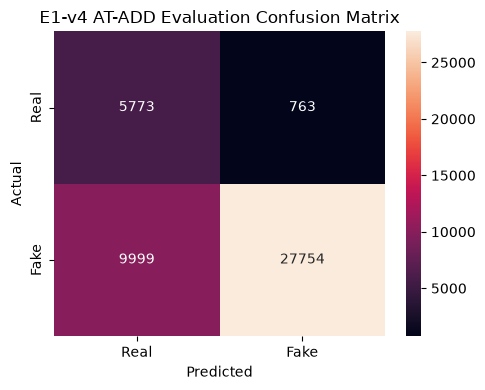

Saved: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/results/figures/E1_ATADD_eval_confusion_matrix_v4.png


In [26]:
# 24.5. AT-ADD generator and type generalization analysis

if len(eval_run_df) and len(eval_scores):

    eval_analysis=eval_run_df[
        [
            "file_id",
            "type",
            "label",
            "generator",
            "source"
        ]
    ].copy()

    eval_analysis["label_id"]=eval_analysis["label"].map(
        LABEL_MAP
    )

    eval_analysis["spoof_score"]=eval_scores
    eval_analysis["prediction"]=(
        eval_scores>=0.5
    ).astype(int)

    train_generators=set(
        train_df.loc[
            train_df["label"]=="fake",
            "generator"
        ]
    )

    dev_generators=set(
        dev_df.loc[
            dev_df["label"]=="fake",
            "generator"
        ]
    )

    eval_generators=set(
        eval_df.loc[
            eval_df["label"]=="fake",
            "generator"
        ]
    )

    print("AT-ADD generator generalization")
    print("-"*50)

    print("Train generators:",len(train_generators))
    print("Dev generators:",len(dev_generators))
    print("Eval generators:",len(eval_generators))

    print(
        "Train ∩ Eval:",
        len(train_generators&eval_generators)
    )

    print(
        "Dev ∩ Eval:",
        len(dev_generators&eval_generators)
    )

    assert len(train_generators&eval_generators)==0
    assert len(dev_generators&eval_generators)==0

    print(
        "Unseen-generator evaluation check: PASS"
    )

    print("\nPer-type evaluation results")
    print("-"*50)

    type_results=[]

    for audio_type,group in eval_analysis.groupby("type"):

        y_true=group["label_id"].to_numpy()
        scores=group["spoof_score"].to_numpy()

        if len(np.unique(y_true))<2:
            continue

        metrics,_=calculate_metrics(
            y_true,
            scores
        )

        type_results.append({
            "type":audio_type,
            "samples":len(group),
            "real_samples":int(
                (y_true==0).sum()
            ),
            "fake_samples":int(
                (y_true==1).sum()
            ),
            "macro_f1":metrics["macro_f1"],
            "auroc":metrics["auroc"],
            "eer":metrics["eer"]
        })

    type_results_df=pd.DataFrame(
        type_results
    )

    display(type_results_df)

    if len(type_results_df):

        overall_type_macro_f1=float(
            type_results_df["macro_f1"].mean()
        )

        print(
            "\nMean per-type Macro-F1:",
            f"{overall_type_macro_f1:.6f}"
        )

        type_results_df.to_csv(
            EXPERIMENT_DIR/
            "E1_ATADD_eval_type_results_v4.csv",
            index=False
        )

    print("\nPer-generator fake-sample results")
    print("-"*50)

    generator_results=[]

    fake_eval=eval_analysis[
        eval_analysis["label"]=="fake"
    ]

    for generator,group in fake_eval.groupby(
        "generator"
    ):

        if generator=="-" or pd.isna(generator):
            continue

        predictions=group["prediction"].to_numpy()
        scores=group["spoof_score"].to_numpy()

        detected=int(
            (predictions==1).sum()
        )

        missed=int(
            (predictions==0).sum()
        )

        generator_results.append({
            "generator":generator,
            "audio_type":group["type"].mode().iloc[0],
            "samples":len(group),
            "fake_detected":detected,
            "fake_missed":missed,
            "fake_recall":detected/len(group),
            "mean_fake_score":scores.mean()
        })

    generator_results_df=pd.DataFrame(
        generator_results
    )

    if len(generator_results_df):

        generator_results_df=generator_results_df.sort_values(
            "fake_recall"
        )

        display(generator_results_df)

        generator_results_df.to_csv(
            EXPERIMENT_DIR/
            "E1_ATADD_eval_generator_results_v4.csv",
            index=False
        )

        print(
            "Saved generator analysis."
        )

    eval_cm=confusion_matrix(
        eval_labels,
        eval_analysis["prediction"].to_numpy()
    )

    plt.figure(figsize=(5,4))

    sns.heatmap(
        eval_cm,
        annot=True,
        fmt="d",
        xticklabels=["Real","Fake"],
        yticklabels=["Real","Fake"]
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title("E1-v4 AT-ADD Evaluation Confusion Matrix")
    plt.tight_layout()

    eval_cm_path=(
        RESULT_FIGURE_DIR/
        "E1_ATADD_eval_confusion_matrix_v4.png"
    )

    plt.savefig(
        eval_cm_path,
        dpi=200
    )

    plt.show()

    print(
        "Saved:",
        eval_cm_path
    )

else:
    print(
        "Evaluation analysis is not available."
    )

## AT-ADD Track 2 evaluation interpretation

The evaluation partition is kept untouched. v4 is compared with E1 using the same AT-ADD evaluation data and metrics, while generator/type fields remain post-inference analysis fields.

In [27]:
# Evaluation failure-case analysis

if len(eval_analysis):

    false_negatives=eval_analysis[
        (eval_analysis["label"]=="fake")&
        (eval_analysis["prediction"]==0)
    ].copy()

    false_positives=eval_analysis[
        (eval_analysis["label"]=="real")&
        (eval_analysis["prediction"]==1)
    ].copy()

    false_negatives=false_negatives.sort_values(
        "spoof_score"
    )

    false_positives=false_positives.sort_values(
        "spoof_score",
        ascending=False
    )

    print("Evaluation failure-case analysis")
    print("-"*50)

    print(
        "\nFalse-negative fake samples:",
        len(false_negatives)
    )

    print(
        "False-positive real samples:",
        len(false_positives)
    )

    print("\nMost confidently missed fake samples")
    print("-"*50)

    display(
        false_negatives[
            [
                "file_id",
                "type",
                "generator",
                "source",
                "spoof_score"
            ]
        ].head(25)
    )

    print("\nMost confidently misclassified real samples")
    print("-"*50)

    display(
        false_positives[
            [
                "file_id",
                "type",
                "generator",
                "source",
                "spoof_score"
            ]
        ].head(25)
    )

    failure_cases=pd.concat(
        [
            false_negatives.head(25).assign(
                error_type="false_negative"
            ),
            false_positives.head(25).assign(
                error_type="false_positive"
            )
        ]
    )

    failure_cases_path=(
        EXPERIMENT_DIR/
        "E1_ATADD_eval_failure_cases_v4.csv"
    )

    failure_cases.to_csv(
        failure_cases_path,
        index=False
    )

    print(
        "\nSaved:",
        failure_cases_path
    )

else:
    print(
        "Evaluation analysis is not available."
    )

Evaluation failure-case analysis
--------------------------------------------------

False-negative fake samples: 9999
False-positive real samples: 763

Most confidently missed fake samples
--------------------------------------------------


,file_id,type,generator,source,spoof_score
2821,ATADD_T2_Eval_185180.flac,music,SSM-TTM,-,1.473040e-09
2771,ATADD_T2_Eval_171875.flac,music,SSM-TTM,-,1.833228e-09
2047,ATADD_T2_Eval_009727.flac,music,SSM-TTM,-,1.997738e-09
2910,ATADD_T2_Eval_209611.flac,music,SSM-TTM,-,2.263734e-09
2699,ATADD_T2_Eval_152611.flac,music,SSM-TTM,-,2.545185e-09
2855,ATADD_T2_Eval_193427.flac,music,SSM-TTM,-,2.585266e-09
2774,ATADD_T2_Eval_172112.flac,music,SSM-TTM,-,3.167534e-09
2144,ATADD_T2_Eval_029793.flac,music,SSM-TTM,-,3.761540e-09
2041,ATADD_T2_Eval_008394.flac,music,SSM-TTM,-,4.262382e-09
2447,ATADD_T2_Eval_100097.flac,music,SSM-TTM,-,5.181739e-09



Most confidently misclassified real samples
--------------------------------------------------


,file_id,type,generator,source,spoof_score
4294,ATADD_T2_Eval_127878.flac,music,-,FMA,1.000000
16716,ATADD_T2_Eval_166179.flac,sound,-,AudioCaps,1.000000
16246,ATADD_T2_Eval_109746.flac,sound,-,VocalSound,1.000000
42777,ATADD_T2_Eval_058775.flac,speech,-,Others,1.000000
16423,ATADD_T2_Eval_130102.flac,sound,-,CompA-R,1.000000
15591,ATADD_T2_Eval_030658.flac,sound,-,TUT2016,0.999999
43363,ATADD_T2_Eval_126362.flac,speech,-,Others,0.999999
16643,ATADD_T2_Eval_158119.flac,sound,-,CompA-R,0.999999
15325,ATADD_T2_Eval_003558.flac,sound,-,CompA-R,0.999999
43461,ATADD_T2_Eval_138796.flac,speech,-,Others,0.999999



Saved: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/E1_v4/E1_ATADD_eval_failure_cases_v4.csv


### Evaluation analysis note

The AT-ADD generator/type analysis is performed in the previous cell.

No speaker-overlap claim is made here because Track 2 metadata uses `-` for some identity fields by design. The primary generalization criterion for this E1 evaluation is the verified unseen-generator split.

# 25. Save the E1 experiment configuration

The final configuration records the model, preprocessing, dataset preparation version and training settings.

This is important because later changes to preprocessing or model design should produce a new experiment version rather than silently changing the meaning of E1.


In [28]:
# 25. Save the complete E1-v4 AT-ADD configuration

config={
    "experiment":"E1-v4",
    "experiment_version":EXPERIMENT_VERSION,
    "input_preprocessing_version":INPUT_PREPROCESSING_VERSION,
    "preprocessing_module":"src/preprocessing/preprocess_atadd_v4.py",
    "dataset_preparation_version":"AT-ADD_manifest_v1",

    "model":{
        "name":"MobileNetV3-Small",
        "weights":"scratch",
        "input_channels":1,
        "num_classes":2,
        "total_parameters":total_params,
        "trainable_parameters":trainable_params
    },

    "dataset":{
        "name":"AT-ADD Track 2",
        "train_manifest":"data/manifests/train_manifest.csv",
        "dev_manifest":"data/manifests/dev_manifest.csv",
        "eval_manifest":"data/manifests/eval_manifest.csv",
        "train_samples":len(train_run_df),
        "dev_samples":len(dev_run_df),
        "eval_samples":len(eval_run_df),
        "label_mapping":LABEL_MAP,
        "unseen_generator_eval":True
    },

    "audio":{
        "sample_rate":SAMPLE_RATE,
        "segment_seconds":SEGMENT_SECONDS,
        "num_samples":NUM_SAMPLES
    },

    "spectrogram":{
        "n_fft":N_FFT,
        "win_length":WIN_LENGTH,
        "hop_length":HOP_LENGTH,
        "n_mels":N_MELS,
        "window":"hann",
        "power":2.0,
        "log_epsilon":LOG_EPS,
        "feature_extraction_device":"cuda" if DEVICE.type=="cuda" else "cpu"
    },

    "training_preprocessing":{
        "train_crop":"random",
        "eval_crop":"center",
        "short_audio":"repeat_pad",
        "normalization":"training_set_mean_std",
        "stft_and_mel":"GPU_batched",
        "feature_normalization":"training_set_global_mean_std"
    },

    "training":{
        "seed":SEED,
        "batch_size":BATCH_SIZE,
        "epochs":EPOCHS,
        "learning_rate":LEARNING_RATE,
        "weight_decay":WEIGHT_DECAY,
        "patience":PATIENCE,
        "loss":"class_weighted_cross_entropy",
        "optimizer":"AdamW",
        "num_workers":NUM_WORKERS,
        "pin_memory":DEVICE.type=="cuda",
        "cudnn_deterministic":True if DEVICE.type=="cuda" else None,
        "cudnn_benchmark":False if DEVICE.type=="cuda" else None
    },

    "excluded_from_E1_v4":[
        "environmental_noise",
        "codec_simulation",
        "telephony_filtering",
        "SpecAugment",
        "robustness_consistency_loss",
        "knowledge_distillation",
        "pruning",
        "quantization",
        "edge_benchmarking"
    ]
}

config_path=EXPERIMENT_DIR/"E1_ATADD_config_v4.json"

with open(
    config_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        config,
        f,
        indent=2
    )

print(
    "Saved configuration:",
    config_path
)

Saved configuration: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/E1_v4/E1_ATADD_config_v4.json


# E1-v4 AT-ADD experiment observations

## Model
MobileNetV3-Small trained from scratch on 80-bin log-Mel spectrograms.

## Dataset
The frozen AT-ADD Track 2 train/dev/eval manifests are used without changing the dataset samples or split assignments.

## v4 input pipeline
The E1 frontend is modified from 16 kHz + zero padding to 24 kHz + repeat-based padding. The 4-second target duration and 80-bin Mel representation are retained.

## Generalization
Overall metrics and per-type Macro-F1 are reported for speech, sound, singing and music. Generator fields are used only for post-inference analysis.

## Experimental boundary
v4 does not include codec simulation, environmental noise, robustness consistency loss, pruning, quantization or edge benchmarking. Those remain outside this baseline/generalization experiment.

# 26. E1 outputs and experiment record

After a successful run, E1 should leave behind four kinds of evidence:

1. **Configuration** - exactly how E1 was run.
2. **Checkpoint** - the selected MobileNetV3-Small model.
3. **Quantitative results** - Macro-F1, AUROC, EER and related metrics.
4. **Analysis artifacts** - predictions, training curves and confusion matrix.

These artifacts will later allow E1 to serve as the reference point for the other baseline and robustness experiments.


In [29]:
# E1-v4 experiment artifact audit

required_artifacts={
    "Best checkpoint":
        CHECKPOINT_DIR/"E1_MobileNetV3Small_ATADD_v4_best.pt",

    "Log-Mel normalization statistics":
        EXPERIMENT_DIR/"E1_ATADD_logmel_stats_v4.json",

    "AT-ADD generator results":
        EXPERIMENT_DIR/"E1_ATADD_eval_generator_results_v4.csv",

    "AT-ADD type results":
        EXPERIMENT_DIR/"E1_ATADD_eval_type_results_v4.csv",

    "Failure-case results":
        EXPERIMENT_DIR/"E1_ATADD_eval_failure_cases_v4.csv",

    "Evaluation confusion matrix":
        RESULT_FIGURE_DIR/"E1_ATADD_eval_confusion_matrix_v4.png",

    "Validation EER figure":
        RESULT_FIGURE_DIR/"E1_ATADD_validation_eer_v4.png"
}

print("E1-v4 AT-ADD experiment artifact audit")
print("-"*50)

all_available=True

for name,path in required_artifacts.items():

    status="OK" if path.exists() else "MISSING"

    print(
        f"{name:<35}: {status}"
    )

    if not path.exists():
        all_available=False

print("-"*50)

if all_available:
    print("All required E1 artifacts are available.")
else:
    print("Some artifacts will appear after the full E1 run.")

E1-v4 AT-ADD experiment artifact audit
--------------------------------------------------
Best checkpoint                    : OK
Log-Mel normalization statistics   : OK
AT-ADD generator results           : OK
AT-ADD type results                : OK
Failure-case results               : OK
Evaluation confusion matrix        : OK
Validation EER figure              : OK
--------------------------------------------------
All required E1 artifacts are available.
